## Задание 2: Удаление продукта

Выполнил: Ларюшкин Кирилл Александрович

Группа: 292605


```bash
python -m venv venv
venv\Scripts\activate
pip install requests
pip freeze > requirements.txt
```

In [2]:
import requests  # Импорт модуля request
import logging  # Импорт модуля logging


# Настройка логирования
logging.basicConfig(
    filename='task2.log',  # Файл куда сохранять логи
    filemode='w',  # Режим - перезаписывать файл с логами при запуске
    level=logging.DEBUG,  # Определениение уровня логирования - уровень логирования DEBUG и выше
    format='%(asctime)s - %(levelname)s - %(message)s',  # Формат логов
    encoding='UTF-8',  # Кодировка UTF-8 , для корректного отображения кириллицы 
)


def add_products(data: dict):
    """ Функция добавления нового продукта
    Принимает словарь с данными нового продукта
    Делает POST запрос к -'https://dummyjson.com/products/add' 
    Выводит сообщение с результатом добавления и id добавленого продукта
    """
    
    try:
        logging.info('Добавление ресурса. Отправка запроса к API...')  # Логирование с информацией об отправке запроса
        url = 'https://dummyjson.com/products/add'  # URL добавления нового поста
        
        response = requests.post(url, json=data, timeout=10)  # POST запрос к API https://dummyjson.com/products/add, с передачей данных data  для добавления нового поста
        response.raise_for_status()  # Контроль статус-кода ответа, вызывает исключение если HTTP вернет ошибку, без него обработка не отработает
    
        logging.info(f'Запрос на добавление обработан, статус-код: {response.status_code}')  # логирование статус кода и результата запроса

        print(f'Продукт добавлен')  # Сообщение с результатом обращения для пользователя
        print(f'Id нового продукта: {response.json()['id']}')  # Вывод на экран id нового продукта
   
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        print(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')
        logging.error(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы        
  
    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        print(f'Произошла ошибка: {e}')  # Выводим сообещние с информацией по ошибке
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы

    except TypeError as e:  # Обрабатывает ошибки при обработки данных
        print(f'Ошибка типа данных:{e}')  # Выводит ошибку на экран
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы


def del_products(product_id: int):
    """ Функция удаления указаного продукта
    Принимает id продукта для удаления
    Делает DELETE запрос к -'https://dummyjson.com/products/{product_id}' 
    Выводит сообщение с результатом удаления, либо информацию отсутствия продукта
    """
    
    try: 
        logging.info('Удаление ресурса. Отправка запроса к API...')  # Логирование с информацией об отправке запроса
        url = f'https://dummyjson.com/products/{product_id}'  # URL с id поста для удаления
        
        response = requests.delete(url, timeout=10)  # DELETE запрос к API https://dummyjson.com/products/{product_id}, с передачей id продукта для удаления
        response.raise_for_status()  # Контроль статус-кода ответа, вызывает исключение если HTTP вернет ошибку, без него обработка не отработает

        logging.info(f'Запрос на удаление обработан, статус-код: {response.status_code}')  # логирование статус кода и результата запроса
        
        print(f'Запрос на удаление продукта {product_id} выполнен.')  # Вывод на экран id удаленного продукта

    
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        print(f'Продукт с id {product_id} отсутствует ')
        logging.error(f'Продукт с id {product_id} отсутствует')  # Логирует ошибку
        exit()  # Прекращает выполнение программы
    
    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        print(f'Произошла ошибка: {e}')  # Выводим сообещние с информацией по ошибке
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы

    except TypeError as e:  # Обрабатывает ошибки при обработки данных
        print(f'Ошибка типа данных:{e}')  # Выводит ошибку на экран
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы


def check_products(product_id: int):
    """ Функция проверяет наличие указаного продукта
    Принимает id продукта для проверки наличия
    Делает GET запрос к -'https://dummyjson.com/products/{product_id}' 
    Выводит сообщение с информацией о продукте, либо информацию отсутствия продукта
    """
    
    try: 
        logging.info('Проверка наличия ресурса. Отправка запроса к API...')  # Логирование с информацией об отправке запроса
        url = f'https://dummyjson.com/products/{product_id}'  # URL с id поста для проверки
        
        response = requests.get(url, timeout=10)  # GET запрос к API https://dummyjson.com/products/{product_id}, с передачей id продукта для получения информации
        response.raise_for_status()  # Контроль статус-кода ответа, вызывает исключение если HTTP вернет ошибку, без него обработка не отработает

        product = response.json()
        
        logging.info(f'Запрос получение данных о продукте обработан, статус-код: {response.status_code}')  # логирование статус кода и результата запроса

    
        print(f'Продукт в наличии. Данные продукта {product_id}: ')  # Вывод на экран id продукта
        print(f'- {product["title"]}: ${product["price"]}')  # Сообщение с данными продукта для пользователя

    
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        print(f'Продукт с id {product_id} отсутствует ')  # Вывод сообщения об отсутвии продукта
        logging.error(f'Продукт с id {product_id} отсутствует')  # Логирует ошибку
        exit()  # Прекращает выполнение программы
    
    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        print(f'Произошла ошибка: {e}')  # Выводим сообещние с информацией по ошибке
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы

    except TypeError as e:  # Обрабатывает ошибки при обработки данных
        print(f'Ошибка типа данных:{e}')  # Выводит ошибку на экран
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы


# Реализация пользовательского интерфейса
while True:
        # Пользовательский ввод
        user_input = input('Введите номер действия, что хотите выполнить:\n 1) Добавить продукт\n 2) Удалить продукт\n 3) Проверка наличия продукта и получение данных\n 4) Для выхода введите "q" ')

        # Условное ветвление
        if user_input == '1': 
            # Пользователь выбрал пункт 1 - Добавить продукт

            # Данные добавляемого продукта
            data = {
                'title': 'New Product',  # Название продукта
                'description': 'This is a new product',  # Описание продукта
                'price': 999.99  # Цена продукта
            }

            logging.info(f'Пользователь ввел {user_input} и выбрал Добавить продукт')  # логирование действий пользователя
    
            add_products(data) # Вызов функции с пердачей данных продукта
    
        elif user_input == '2':
            # Пользователь выбрал пункт 2 - Удалить продукт
            
            product_id = input('Введите номер id продукта для удаления: ')  # Пользовательский ввод id продукта для удаления
            logging.info(f'Пользователь ввел {user_input} и выбрал Удалить продукт с id {product_id}')  # логирование действий пользователя
            del_products(product_id)  # Вызов функции с пердачей id продукта
            
        elif user_input == '3':
            # Пользователь выбрал пункт 3 - Проверка наличия продукта
            product_id = input('Введите номер id продукта для проверки наличия: ')  # Пользовательский ввод id продукта для проверки наличия и получения данных
            
            logging.info(f'Пользователь ввел {user_input} и выбрал Проверить наличие продукта с id {product_id}')  # логирование действий пользователя
            
            check_products(product_id)  # Вызов функции с пердачей id продукта
            
        elif user_input == 'q':
            print('Работа программы завершена')  # Выводит информацию по завершению программы
            logging.error('Работа программы завершена')  # Логируем завершение программы
            break  # Завершаем работу программы
            
        else:
            logging.info(f'Пользователь ввел {user_input}. Некорректный ввод')  # логирование действий пользователя
            # Вывод сообщения при некорректном вводе от пользователя
            print('Некорректый ввод. Введите номер действия в виде цифры (1,2,3), а что бы выйти введите "q"') 



Введите номер действия, что хотите выполнить:
 1) Добавить продукт
 2) Удалить продукт
 3) Проверка наличия продукта и получение данных
 4) Для выхода введите "q"  1


Продукт добавлен
Id нового продукта: 195


Введите номер действия, что хотите выполнить:
 1) Добавить продукт
 2) Удалить продукт
 3) Проверка наличия продукта и получение данных
 4) Для выхода введите "q"  2
Введите номер id продукта для удаления:  11


Запрос на удаление продукта 11 выполнен.


Введите номер действия, что хотите выполнить:
 1) Добавить продукт
 2) Удалить продукт
 3) Проверка наличия продукта и получение данных
 4) Для выхода введите "q"  2
Введите номер id продукта для удаления:  195


Продукт с id 195 отсутствует 


... (6 outputs left out)

Введите номер действия, что хотите выполнить:
 1) Добавить продукт
 2) Удалить продукт
 3) Проверка наличия продукта и получение данных
 4) Для выхода введите "q"  3
Введите номер id продукта для проверки наличия:  195


Продукт с id 195 отсутствует 


Введите номер действия, что хотите выполнить:
 1) Добавить продукт
 2) Удалить продукт
 3) Проверка наличия продукта и получение данных
 4) Для выхода введите "q"  q


Работа программы завершена


```bash
deactivate
```

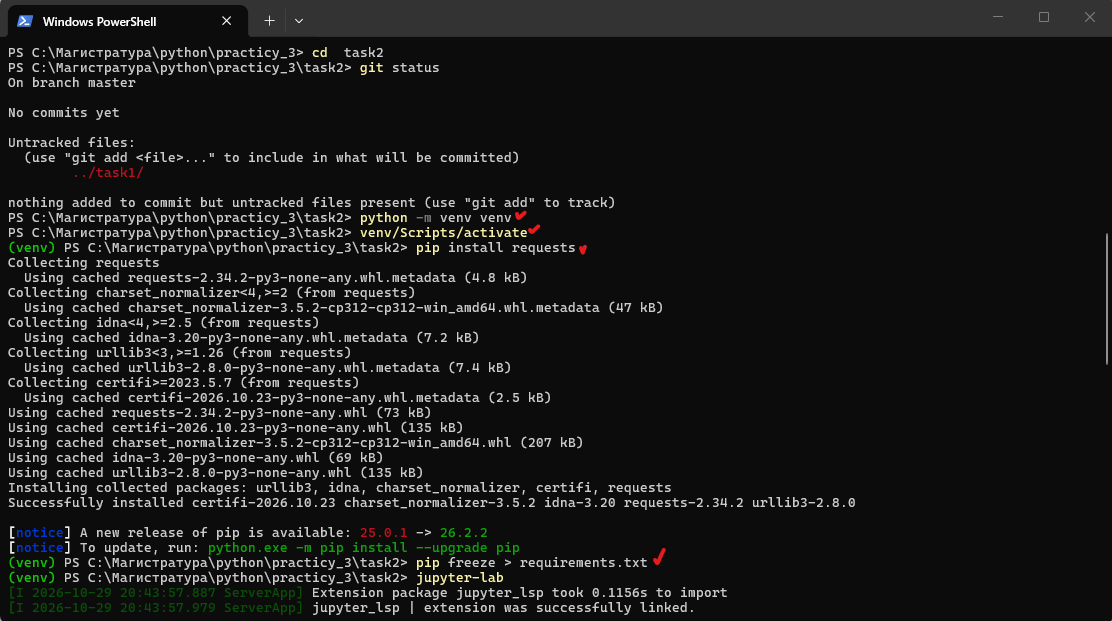

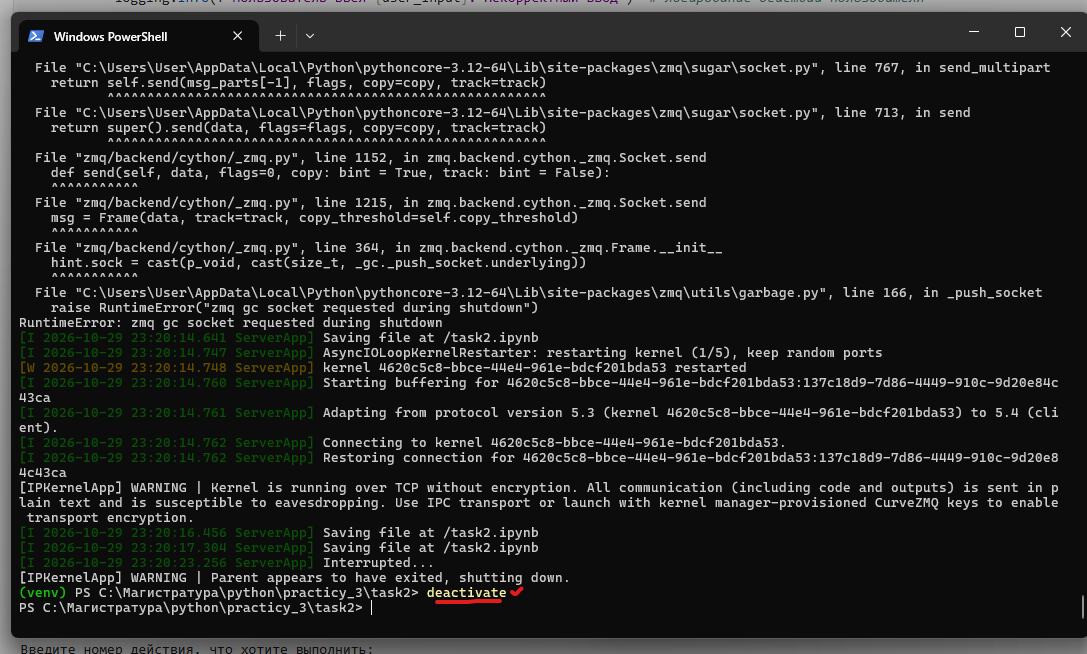